# Week 12 – Capstone: Customer Churn Prediction

**Problem:** A telecom company loses revenue when customers leave ("churn"). Can we predict which customers are likely to leave, so the company can act before they go?

**Data:** Telco Customer Churn dataset, 7,043 customers, 20 features (contract, tenure, services, charges) and a Yes/No churn label.

**Pipeline:** data → cleaning → EDA → modelling → evaluation → simple deployment (Streamlit).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Cleaning
`TotalCharges` is stored as text and has 11 blank values. These are brand-new customers (tenure = 0) who haven't been billed yet, so I convert the column to numbers and fill those blanks with 0. `customerID` is just an identifier, so I drop it.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges"]].head())

df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns=["customerID"])
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print(df.isna().sum().sum(), "missing values left")

Blank TotalCharges: 11
      tenure  MonthlyCharges
488        0           52.55
753        0           20.25
936        0           80.85
1082       0           25.75
1340       0           56.05
0 missing values left


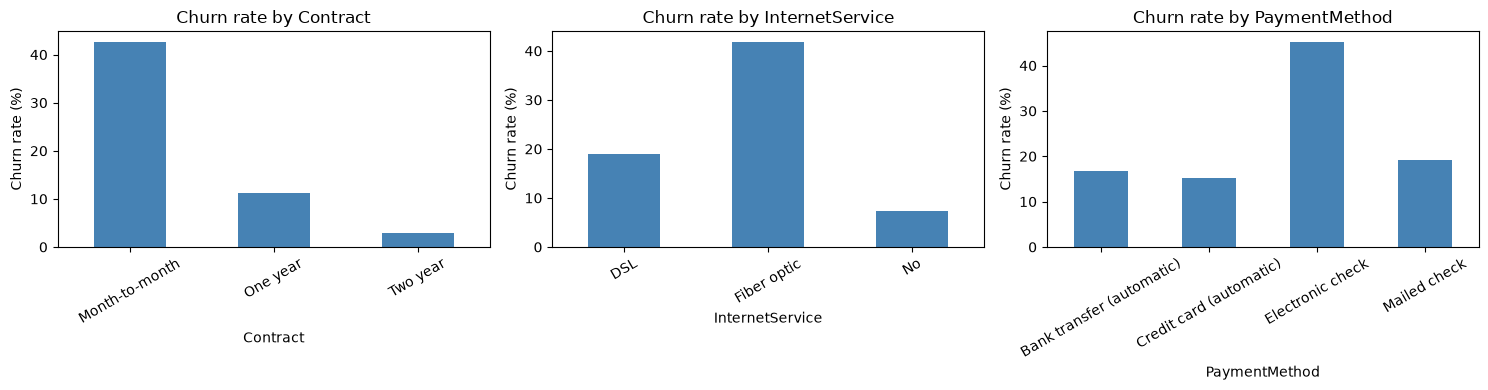

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    (df.groupby(col)["Churn"].mean() * 100).plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

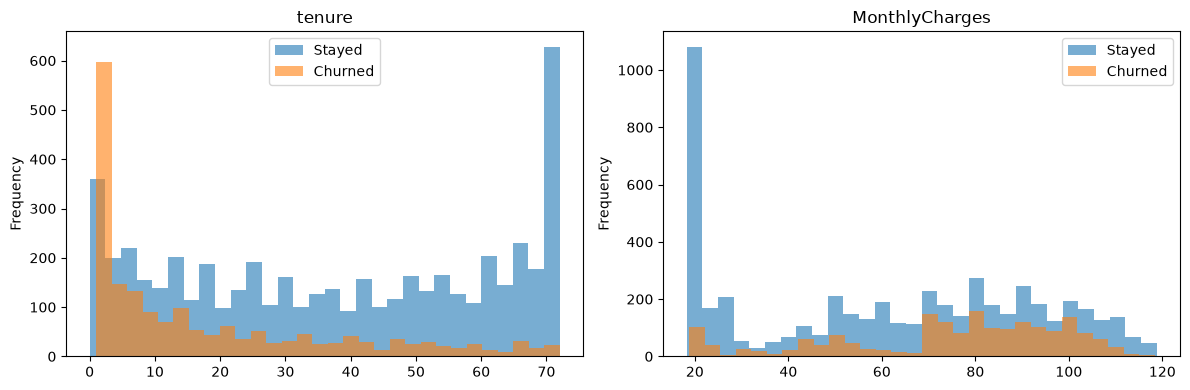

       tenure  MonthlyCharges
Churn                        
0        37.6            61.3
1        18.0            74.4


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges"]):
    df[df["Churn"] == 0][col].plot(kind="hist", bins=30, alpha=0.6, ax=ax, label="Stayed")
    df[df["Churn"] == 1][col].plot(kind="hist", bins=30, alpha=0.6, ax=ax, label="Churned")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1))

### EDA findings
- Month-to-month customers churn far more than customers on one- or two-year contracts
- Fiber optic customers and electronic-check payers churn more
- Churned customers have a much shorter tenure and higher monthly charges

## Modelling
I use a scikit-learn Pipeline so that scaling and encoding are learned from the training data only (no data leakage, as learned in Week 7). Text columns are one-hot encoded, numeric columns are scaled.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

rows = []
for name, m in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", m)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, prob)})

baseline = pd.DataFrame(rows).round(4)
baseline

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8420
1,Decision Tree,0.7984,0.6347,0.5668,0.5989,0.8297
2,Random Forest,0.7828,0.6164,0.4813,0.5405,0.8196


## Tuning
Missing a customer who is about to leave (low recall) costs the business more than a false alarm, so I use `class_weight="balanced"` and tune for F1 with 5-fold cross-validation.

In [8]:
from sklearn.model_selection import GridSearchCV

lr_search = GridSearchCV(
    Pipeline([("prep", preprocess),
              ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    {"model__C": [0.01, 0.1, 1, 10]},
    cv=5, scoring="f1", n_jobs=-1
).fit(X_train, y_train)

rf_search = GridSearchCV(
    Pipeline([("prep", preprocess),
              ("model", RandomForestClassifier(random_state=42, class_weight="balanced"))]),
    {"model__n_estimators": [100, 300],
     "model__max_depth": [5, 8, None],
     "model__min_samples_leaf": [1, 5]},
    cv=5, scoring="f1", n_jobs=-1
).fit(X_train, y_train)

print("LR best:", lr_search.best_params_, round(lr_search.best_score_, 4))
print("RF best:", rf_search.best_params_, round(rf_search.best_score_, 4))

LR best: {'model__C': 0.1} 0.6326
RF best: {'model__max_depth': 8, 'model__min_samples_leaf': 5, 'model__n_estimators': 100} 0.6352


In [9]:
best_lr, best_rf = lr_search.best_estimator_, rf_search.best_estimator_

rows = []
for name, m in [("Logistic Regression (tuned)", best_lr), ("Random Forest (tuned)", best_rf)]:
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, prob)})
tuned = pd.DataFrame(rows).round(4)
tuned

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression (tuned),0.7417,0.5087,0.7861,0.6176,0.8408
1,Random Forest (tuned),0.7509,0.5204,0.7861,0.6262,0.8420


Final model: Random Forest


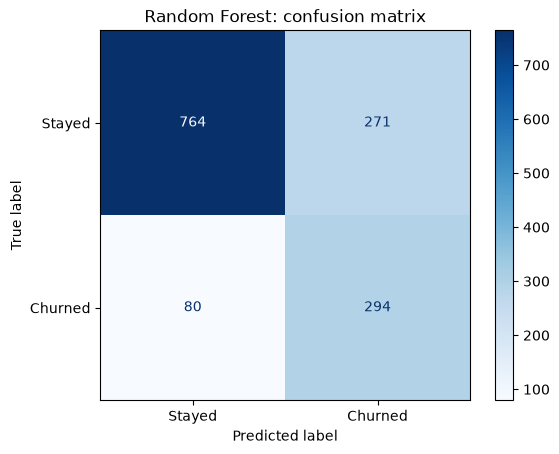

              precision    recall  f1-score   support

      Stayed       0.91      0.74      0.81      1035
     Churned       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

f1_lr = f1_score(y_test, best_lr.predict(X_test))
f1_rf = f1_score(y_test, best_rf.predict(X_test))
final_name, final_model = ("Random Forest", best_rf) if f1_rf >= f1_lr else ("Logistic Regression", best_lr)
print("Final model:", final_name)

ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test,
                                      display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title(f"{final_name}: confusion matrix")
plt.show()
print(classification_report(y_test, final_model.predict(X_test), target_names=["Stayed", "Churned"]))

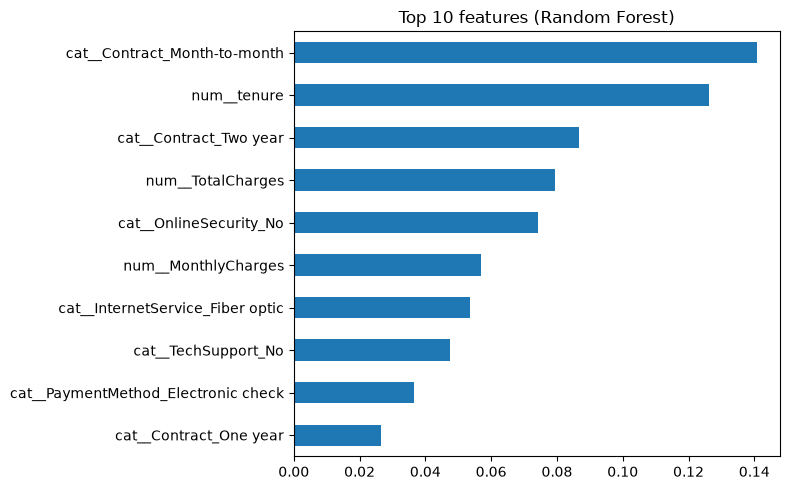

In [11]:
est = final_model.named_steps["model"]
names = final_model.named_steps["prep"].get_feature_names_out()
imp = pd.Series(est.coef_[0] if hasattr(est, "coef_") else est.feature_importances_, index=names)
top = imp.reindex(imp.abs().sort_values(ascending=False).index)[:10]

top[::-1].plot(kind="barh", figsize=(8, 5), title=f"Top 10 features ({final_name})")
plt.tight_layout()
plt.show()

In [12]:
import joblib

options = {c: sorted(X[c].unique().tolist()) for c in cat_cols}
joblib.dump({"model": final_model, "columns": X.columns.tolist(), "options": options},
            "churn_model.joblib")
print("Saved churn_model.joblib")

Saved churn_model.joblib
